<a href="https://colab.research.google.com/github/juuaann09/Metodos/blob/main/MetodoDeBiseccion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Método de Neville**

# Interpolación Iterada: Método de Neville (Burden, Algoritmo 3.1)

El **método de Neville** permite evaluar el polinomio de interpolación de Lagrange de grado $n$ en un punto específico $x$, generando aproximaciones sucesivas de grado creciente sin construir la fórmula algebraica explícita.

### Fórmula:
Dados $n+1$ puntos distintos $(x_0, y_0), (x_1, y_1), \dots, (x_n, y_n)$, construimos una matriz triangular inferior $Q$ de tamaño $(n+1) \times (n+1)$:

1. **Inicialización (Grado 0):** $Q_{i,0} = y_i$ para cada $i = 0, 1, \dots, n$.
2. **Iteración (Grados $1$ a $n$):** Para cada $i = 1, 2, \dots, n$ y $j = 1, 2, \dots, i$:

$$Q_{i,j} = \frac{(x - x_{i-j}) Q_{i, j-1} - (x - x_i) Q_{i-1, j-1}}{x_i - x_{i-j}}$$

El valor final interpolado se encuentra en la esquina inferior derecha de la matriz: $Q_{n,n}$.


####**Ejemplo 2 (Burden, Sección 3.2).**
Se busca aproximar el valor de una función desconocida $f(x)$ en el punto **$x = 1.5$** utilizando el **método de Neville**.




In [14]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

Definiendo datos del ejemplo:

In [15]:
numx = [1.0, 1.3, 1.6, 1.9, 2.2]
val = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]
x = sp.Float(1.5)

Empezamos a utilizar el método Neville realizando la tabla.

In [16]:
def neville(x, numx, val):
    n = len(numx)
    Q = sp.zeros(n, n)

    for i in range(n):
        Q[i, 0] = sp.Float(val[i], 8)

    for i in range(1, n):
        for j in range(1, i + 1):
            Q[i, j] = sp.N(
                ((x - numx[i-j]) * Q[i, j-1]
                - (x - numx[i]) * Q[i-1, j-1])
                / (numx[i] - numx[i-j]), 8
            )

    return Q, Q[n-1, n-1]

Aplicamos el método Neville:

In [17]:
Q, resultado = neville(x, numx, val)

In [18]:
print("Tabla de Neville:")
sp.pprint(Q)

print("Aproximacion de f(1.5):")
print(resultado)

Tabla de Neville:
⎡0.7651977      0           0           0          0   ⎤
⎢                                                      ⎥
⎢0.620086   0.52334487      0           0          0   ⎥
⎢                                                      ⎥
⎢0.4554022  0.5102968   0.51247148      0          0   ⎥
⎢                                                      ⎥
⎢0.2818186  0.5132634   0.51128567  0.51181269     0   ⎥
⎢                                                      ⎥
⎣0.1103623   0.510427   0.51373613  0.51183022  0.51182⎦
Aproximacion de f(1.5):
0.51182000


Graficamos para mejor visulización del ejemplo:

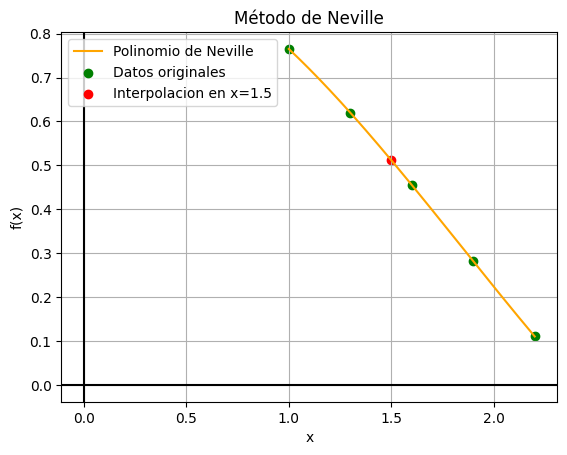

In [25]:
xx = np.linspace(1.0, 2.2, 200)

yy = [float(neville(sp.Float(t), numx, val)[1])
      for t in xx]

plt.plot(xx, yy, label='Polinomio de Neville', color='orange')
plt.scatter(numx, val, color='green', label='Datos originales')
plt.scatter([1.5], [float(resultado)], color='red',
            label='Interpolacion en x=1.5')

plt.axhline(y=0, color='black')
plt.axvline(x=0, color='black')

plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Método de Neville')
plt.legend()
plt.grid()
plt.show()